# Lab 1.12 · Arithmetic intensity and the roofline

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why do two operations on the same GPU hit different ceilings?

The hardware ratio `peak FLOP/s ÷ bandwidth bytes/s` gives a **ridge point** in FLOP per byte. An operation's **arithmetic intensity** is its total FLOP divided by bytes moved across a specified memory boundary. Below the ridge, the bandwidth ceiling is `intensity × bandwidth`. Above it, the compute peak sets the roof. This lab uses an illustrative device with 60 TFLOP/s and 1 TB/s, so the ridge is 60 FLOP/byte. The book uses the same calculation with an H100 example.

For a matrix product `(M × K) @ (K × N)`, count about `2MKN` FLOP using two per multiply-accumulate. In an idealized traffic model, read both inputs once and write the output once. At FP16, the total is `2(MK + KN + MN)` bytes. For M=2, K=3, N=4 that gives 48 FLOP and 52 bytes. Real traffic depends on tiling, caching, and data layout.

Use rates and byte counts for the same memory boundary. For example, compare DRAM traffic with DRAM bandwidth. The roof is an upper bound on throughput. A point below it may reflect overhead or an implementation that does not saturate either resource.

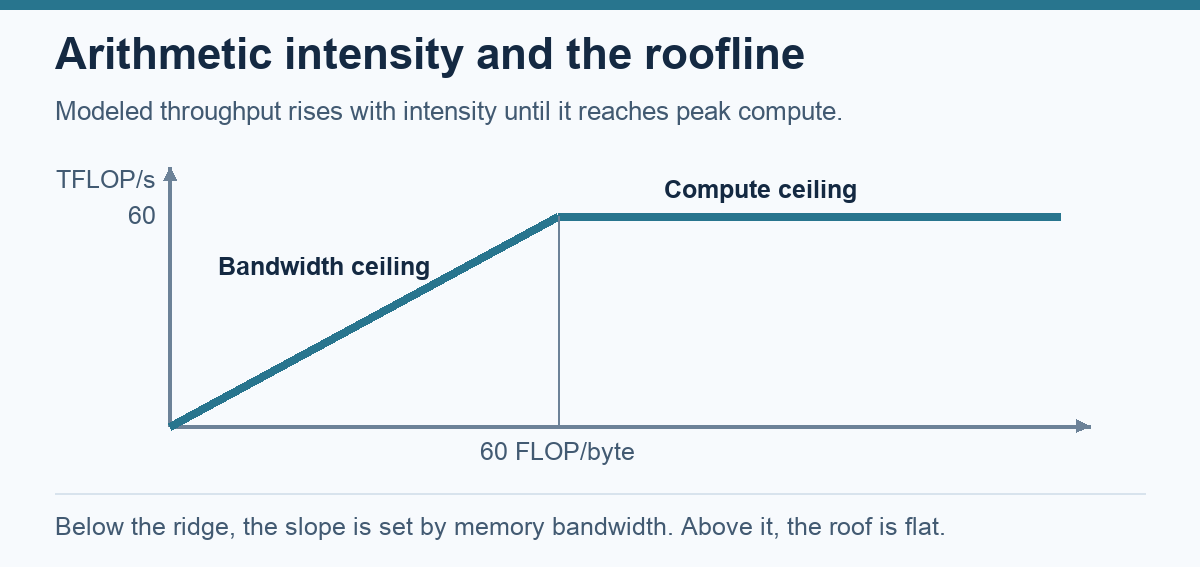

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Count matmul work | Calculate FLOP and modeled memory traffic. | How does reuse change as M grows? |
| 2. Apply the roofline | Convert intensity into a throughput ceiling. | Where does the ceiling stop rising? |

Reading companion for Section 2.4.1, pp. 62–63 of *Inference Engineering* by Philip Kiely (Baseten Books).

In [ ]:
from math import isclose

peak, bandwidth = 60e12, 1e12
ridge = peak / bandwidth
print("Ridge:", ridge, "FLOP/byte")

## Exercise 1. Count FLOP and bytes

Return a pair (operations, traffic_bytes). The inputs and output have the same bytes per value. Include the output write. Predict whether increasing M makes the shared K × N input larger.

**Implementation hint** · List the shapes of the two inputs and the output, multiply the dimensions of each, then convert their combined element count to bytes.

**Interpret the result** · The shared K × N matrix stays fixed. As M grows, its cost is spread over more rows, though input and output traffic also grow.

In [ ]:
def matmul_cost(m, k, n, bytes_per_value=2):
    return None

In [ ]:
tiny = matmul_cost(2, 3, 4)
if tiny is not None:
    assert tiny == (48, 52)
    for m in (1, 16, 128, 512):
        operations, moved = matmul_cost(m, 1024, 1024)
        print(m, "rows:", round(operations / moved, 1), "FLOP/byte")
    print("PASS — counted both reads and the output write")
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

## Exercise 2. Find the roof

For a given intensity, return the smaller of the bandwidth ceiling and compute peak, in FLOP/s. Evaluate the matmul points from Exercise 1. Predict which one first exceeds the ridge.

**Implementation hint** · Both ceilings must be expressed in FLOP/s before taking their minimum.

**Interpret the result** · The 16-row case is below the ridge. The 128-row case is above it and is capped at 60 TFLOP/s.

In [ ]:
def roof(intensity, peak, bandwidth):
    return None

In [ ]:
if tiny is not None and roof(1, peak, bandwidth) is not None:
    assert roof(1, peak, bandwidth) == bandwidth
    assert roof(ridge, peak, bandwidth) == peak
    assert roof(2 * ridge, peak, bandwidth) == peak
    for m in (1, 16, 128, 512):
        operations, moved = matmul_cost(m, 1024, 1024)
        ai = operations / moved
        print(f"M={m:3d}  AI={ai:6.1f}  roof={roof(ai, peak, bandwidth) / 1e12:5.1f} TFLOP/s")
    print("PASS — the ceiling plateaus at the compute peak")
else:
    print("Complete the implementation and any earlier exercises, then rerun this check.")

## Wrap-up

Change the assumed bytes per element to one. How does the intensity change if FLOP count and peak stay fixed? Why would a real precision change require checking the compute peak again?